# Predictive maintenance: EDA and machine-week table

**Target grain of the modeling table: 1 row per (`machineID`, `week_start`).**

Data: Microsoft Azure Predictive Maintenance (Kaggle `arnabbiswas1/microsoft-azure-predictive-maintenance`), 5 CSVs.

| Table | Grain (raw) |
|---|---|
| `telemetry` | 1 row per (`datetime`, `machineID`), hourly sensor readings |
| `errors` | 1 row per (`datetime`, `machineID`, `errorID`) |
| `maint` | 1 row per (`datetime`, `machineID`, `comp`), component replacement |
| `failures` | 1 row per (`datetime`, `machineID`, `failure`), component failure |
| `machines` | 1 row per `machineID` (static: model, age) |

In [36]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

# Uses the local kagglehub cache when the files are already there
path = kagglehub.dataset_download("arnabbiswas1/microsoft-azure-predictive-maintenance")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\ferna\.cache\kagglehub\datasets\arnabbiswas1\microsoft-azure-predictive-maintenance\versions\3


In [37]:
dfs = {
    f.removeprefix("PdM_").removesuffix(".csv"): pd.read_csv(os.path.join(path, f))
    for f in sorted(os.listdir(path))
    if f.endswith(".csv")
}
for df in dfs.values():
    if "datetime" in df.columns:
        df["datetime"] = pd.to_datetime(df["datetime"])

telemetry, errors, maint, failures, machines = (
    dfs["telemetry"], dfs["errors"], dfs["maint"], dfs["failures"], dfs["machines"]
)
findings = []  # (table, issue, rows, decision)

## 1. EDA
### Shapes and dtypes

In [38]:
for name, df in dfs.items():
    print(f"\n{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(df.dtypes.to_string())


errors: 3,919 rows x 3 columns
datetime     datetime64[us]
machineID             int64
errorID                 str

failures: 761 rows x 3 columns
datetime     datetime64[us]
machineID             int64
failure                 str

machines: 100 rows x 3 columns
machineID    int64
model          str
age          int64

maint: 3,286 rows x 3 columns
datetime     datetime64[us]
machineID             int64
comp                    str

telemetry: 876,100 rows x 6 columns
datetime     datetime64[us]
machineID             int64
volt                float64
rotate              float64
pressure            float64
vibration           float64


### Null %

In [39]:
null_pct = pd.concat(
    {name: df.isna().mean().mul(100).round(3) for name, df in dfs.items()}, names=["table", "column"]
).rename("null_%").to_frame()
null_pct

null_%
table     column           
errors    datetime      0.0
          machineID     0.0
          errorID       0.0
failures  datetime      0.0
          machineID     0.0
          failure       0.0
machines  machineID     0.0
          model         0.0
          age           0.0
maint     datetime      0.0
          machineID     0.0
          comp          0.0
telemetry datetime      0.0
          machineID     0.0
          volt          0.0
          rotate        0.0
          pressure      0.0
          vibration     0.0

### Duplicates
Full-row duplicates and duplicates on each table's natural key.

In [40]:
KEYS = {
    "telemetry": ["datetime", "machineID"],
    "errors": ["datetime", "machineID", "errorID"],
    "maint": ["datetime", "machineID", "comp"],
    "failures": ["datetime", "machineID", "failure"],
    "machines": ["machineID"],
}
dup_summary = pd.DataFrame({
    name: {
        "rows": len(df),
        "full_row_dups": df.duplicated().sum(),
        "key": ", ".join(KEYS[name]),
        "key_dups": df.duplicated(KEYS[name]).sum(),
        "n_machines": df["machineID"].nunique(),
    }
    for name, df in dfs.items()
}).T
dup_summary

,rows,full_row_dups,key,key_dups,n_machines
errors,3919,0,"datetime, machineID, errorID",0,100
failures,761,0,"datetime, machineID, failure",0,98
machines,100,0,machineID,0,100
maint,3286,0,"datetime, machineID, comp",0,100
telemetry,876100,0,"datetime, machineID",0,100


### Cardinality of categorical columns

In [41]:
for name, col in [("errors", "errorID"), ("maint", "comp"), ("failures", "failure"), ("machines", "model")]:
    print(f"{name}.{col}:", dfs[name][col].value_counts().sort_index().to_dict())

errors.errorID: {'error1': 1010, 'error2': 988, 'error3': 838, 'error4': 727, 'error5': 356}
maint.comp: {'comp1': 804, 'comp2': 863, 'comp3': 808, 'comp4': 811}
failures.failure: {'comp1': 192, 'comp2': 259, 'comp3': 131, 'comp4': 179}
machines.model: {'model1': 16, 'model2': 17, 'model3': 35, 'model4': 32}


### Date ranges

In [42]:
date_ranges = pd.DataFrame({
    name: {
        "min": df["datetime"].min(),
        "max": df["datetime"].max(),
        "span_days": (df["datetime"].max() - df["datetime"].min()).days,
        "n_unique_ts": df["datetime"].nunique(),
    }
    for name, df in dfs.items() if "datetime" in df.columns
}).T
date_ranges

,min,max,span_days,n_unique_ts
errors,2015-01-01 06:00:00,2016-01-01 05:00:00,364,2720
failures,2015-01-02 03:00:00,2015-12-31 06:00:00,363,302
maint,2014-06-01 06:00:00,2016-01-01 06:00:00,579,374
telemetry,2015-01-01 06:00:00,2016-01-01 06:00:00,365,8761


Telemetry is meant to be a complete hourly grid. Check the readings per machine against the expected hour count,
and whether non-telemetry events fall outside the telemetry window.

In [43]:
expected_hours = pd.date_range(telemetry["datetime"].min(), telemetry["datetime"].max(), freq="h").size
per_machine = telemetry.groupby("machineID").size()
print(f"Expected hourly readings per machine: {expected_hours:,}")
print(f"Readings per machine: min {per_machine.min():,}, max {per_machine.max():,}")
print(f"Machines with gaps: {(per_machine < expected_hours).sum()}")

tel_min, tel_max = telemetry["datetime"].min(), telemetry["datetime"].max()
for name in ("errors", "maint", "failures"):
    outside = (~dfs[name]["datetime"].between(tel_min, tel_max)).sum()
    print(f"{name}: {outside:,} rows outside the telemetry window")
    if outside:
        findings.append((name, "Events before/after the telemetry window", outside,
                         "Kept: pre-2015 replacements are still useful for time-since-last-maintenance features"))

Expected hourly readings per machine: 8,761
Readings per machine: min 8,761, max 8,761
Machines with gaps: 0
errors: 0 rows outside the telemetry window
maint: 400 rows outside the telemetry window
failures: 0 rows outside the telemetry window


### Sensor distributions

,count,mean,std,min,25%,50%,75%,max
volt,876100.0,170.777736,15.509114,97.333604,160.304927,170.607338,181.004493,255.124717
rotate,876100.0,446.605119,52.673886,138.432075,412.305714,447.558150,482.176600,695.020984
pressure,876100.0,100.858668,11.048679,51.237106,93.498181,100.425559,107.555231,185.951998
vibration,876100.0,40.385007,5.370361,14.877054,36.777299,40.237247,43.784938,76.791072


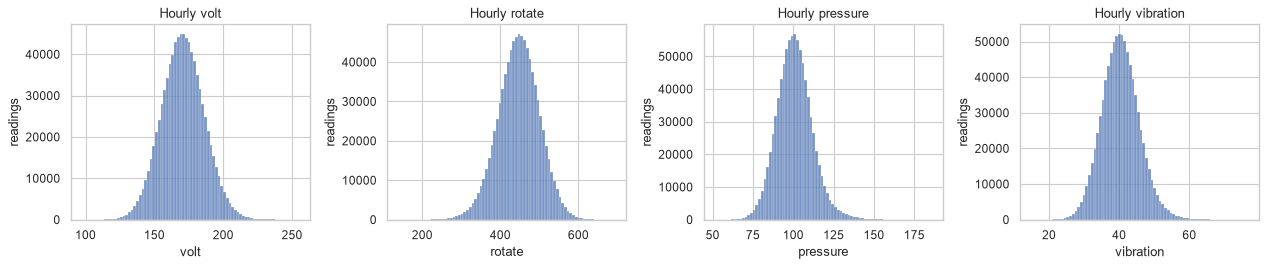

In [44]:
SENSORS = ["volt", "rotate", "pressure", "vibration"]
display(telemetry[SENSORS].describe().T)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, s in zip(axes, SENSORS):
    sns.histplot(telemetry[s], bins=80, ax=ax)
    ax.set(title=f"Hourly {s}", xlabel=s, ylabel="readings")
plt.tight_layout()

### Machine age distribution

,count,mean,std,min,25%,50%,75%,max
age,100.0,11.33,5.856974,0.0,6.75,12.0,16.0,20.0


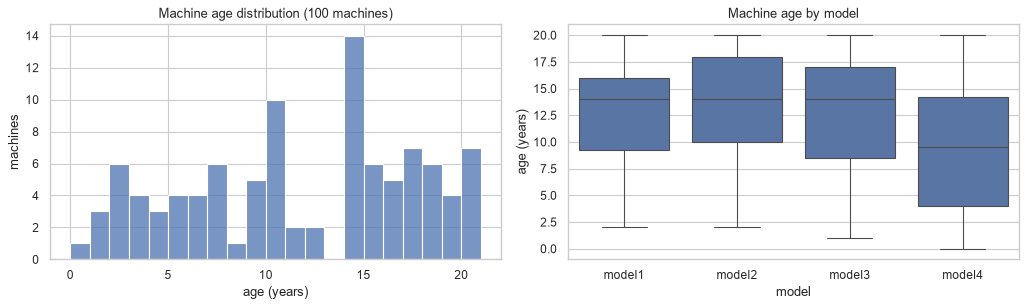

In [45]:
display(machines["age"].describe().to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(machines["age"], bins=range(0, machines["age"].max() + 2), ax=axes[0])
axes[0].set(title="Machine age distribution (100 machines)", xlabel="age (years)", ylabel="machines")
sns.boxplot(data=machines, x="model", y="age", order=sorted(machines["model"].unique()), ax=axes[1])
axes[1].set(title="Machine age by model", xlabel="model", ylabel="age (years)")
plt.tight_layout()

## 2. Machine-week aggregation of telemetry

**Week definition:** calendar weeks Monday 00:00 to Sunday 23:00, keyed by `week_start` (the Monday).
The first and last weeks are partial because telemetry starts on Thu 2015-01-01 06:00 and ends on Fri 2016-01-01 06:00.
`tel_n_hours` records how many hourly readings went into each row (a full week = 168) so partial weeks can be filtered out or down-weighted later.

In [46]:
telemetry["week_start"] = telemetry["datetime"].dt.to_period("W-SUN").dt.start_time

tel_week = telemetry.groupby(["machineID", "week_start"])[SENSORS].agg(["mean", "max", "min", "std"])
tel_week.columns = [f"tel_{s}_{stat}" for s, stat in tel_week.columns]
tel_week["tel_n_hours"] = telemetry.groupby(["machineID", "week_start"]).size()
tel_week = tel_week.reset_index()

# Grain checks
assert not tel_week.duplicated(["machineID", "week_start"]).any()
assert tel_week["tel_n_hours"].sum() == len(telemetry)
n_weeks = tel_week["week_start"].nunique()
assert len(tel_week) == telemetry["machineID"].nunique() * n_weeks, "not every machine has every week"

print(f"telemetry {len(telemetry):,} hourly rows -> tel_week {len(tel_week):,} machine-week rows "
      f"({telemetry['machineID'].nunique()} machines x {n_weeks} weeks)")
print("Hours per week:", tel_week["tel_n_hours"].value_counts().sort_index().to_dict())
tel_week.head()

telemetry 876,100 hourly rows -> tel_week 5,300 machine-week rows (100 machines x 53 weeks)
Hours per week: {90: 100, 103: 100, 168: 5100}


,machineID,week_start,tel_volt_mean,tel_volt_max,tel_volt_min,tel_volt_std,tel_rotate_mean,tel_rotate_max,tel_rotate_min,tel_rotate_std,tel_pressure_mean,tel_pressure_max,tel_pressure_min,tel_pressure_std,tel_vibration_mean,tel_vibration_max,tel_vibration_min,tel_vibration_std,tel_n_hours
0,1,2014-12-29,171.235421,215.656488,129.016707,14.668930,449.377895,568.972310,346.149335,42.211112,99.145831,127.014498,75.237905,10.452246,45.219526,66.764515,25.990511,8.283167,90
1,1,2015-01-05,170.868670,213.787102,121.502718,14.857720,450.907583,586.945963,307.175549,45.002798,100.110713,126.464580,72.851896,9.785422,40.781943,59.577251,29.031392,5.624258,168
2,1,2015-01-12,175.759659,237.938518,119.059047,19.169846,453.681019,586.643332,283.244579,51.280381,100.107587,123.952205,58.733724,10.884855,40.140328,52.884798,27.105512,4.690182,168
3,1,2015-01-19,167.748955,195.838277,127.034797,13.434507,455.294024,574.777950,313.321681,47.455377,99.591135,129.155678,74.646718,9.892967,39.852130,53.039957,26.584752,5.133434,168
4,1,2015-01-26,175.734767,225.189485,126.399891,17.604431,450.342761,575.928307,332.930790,48.805044,99.346233,123.886769,68.823290,10.809546,39.449933,51.164886,26.877399,4.638918,168


In [47]:
partial = (tel_week["tel_n_hours"] < 168).sum()
findings.append(("tel_week", "Partial first/last weeks (< 168 hourly readings)", partial,
                 "Kept, with tel_n_hours so they can be filtered"))

## 3. Join machine attributes
`machines` is 1 row per `machineID`, so it joins many-to-one onto the machine-week table.

In [48]:
def checked_merge(left, right, on, validate="many_to_one", name=""):
    """Left join that asserts no row explosion and logs counts."""
    out = left.merge(right, on=on, how="left", validate=validate, indicator=True)
    unmatched = (out.pop("_merge") == "left_only").sum()
    print(f"{name}: {len(left):,} -> {len(out):,} rows | unmatched: {unmatched:,}")
    assert len(out) == len(left)
    return out

machine_week = checked_merge(
    tel_week, machines.rename(columns={"model": "mach_model", "age": "mach_age"}),
    on="machineID", name="tel_week + machines",
)
assert not machine_week.duplicated(["machineID", "week_start"]).any()
machine_week.shape

tel_week + machines: 5,300 -> 5,300 rows | unmatched: 0


(5300, 21)

In [49]:
tel_week = tel_week.drop(columns=["tel_n_hours"])

In [50]:
errors["week_start"] = errors["datetime"].dt.to_period("W-SUN").dt.start_time
maint["week_start"] = maint["datetime"].dt.to_period("W-SUN").dt.start_time
failures["week_start"] = failures["datetime"].dt.to_period("W-SUN").dt.start_time


In [51]:
# Binary flag: 1 if the machine had at least one failure that week (any component, any count), else 0
fail_week = (
    failures[["machineID", "week_start"]]
    .drop_duplicates()
    .assign(tgt_failure_week=1)
)

# "unmatched" here = machine-weeks with no failure, which is expected
machine_week = checked_merge(
    machine_week.drop(columns="tgt_failure_week", errors="ignore"), fail_week,
    on=["machineID", "week_start"], validate="one_to_one", name="machine_week + failures",
)
machine_week["tgt_failure_week"] = machine_week["tgt_failure_week"].fillna(0).astype(int)

# Every failure week must land on a machine-week row
assert machine_week["tgt_failure_week"].sum() == len(fail_week)
print(f"{len(failures):,} failures -> {len(fail_week):,} machine-weeks with >=1 failure")
machine_week["tgt_failure_week"].value_counts().to_frame().assign(pct=lambda d: (d["count"] / d["count"].sum() * 100).round(2))

machine_week + failures: 5,300 -> 5,300 rows | unmatched: 4,582
761 failures -> 718 machine-weeks with >=1 failure


,count,pct
tgt_failure_week,,
0,4582,86.45
1,718,13.55


In [52]:
machine_week

,machineID,week_start,tel_volt_mean,tel_volt_max,tel_volt_min,tel_volt_std,tel_rotate_mean,tel_rotate_max,tel_rotate_min,tel_rotate_std,...,tel_pressure_min,tel_pressure_std,tel_vibration_mean,tel_vibration_max,tel_vibration_min,tel_vibration_std,tel_n_hours,mach_model,mach_age,tgt_failure_week
0,1,2014-12-29,171.235421,215.656488,129.016707,14.668930,449.377895,568.972310,346.149335,42.211112,...,75.237905,10.452246,45.219526,66.764515,25.990511,8.283167,90,model3,18,0
1,1,2015-01-05,170.868670,213.787102,121.502718,14.857720,450.907583,586.945963,307.175549,45.002798,...,72.851896,9.785422,40.781943,59.577251,29.031392,5.624258,168,model3,18,1
2,1,2015-01-12,175.759659,237.938518,119.059047,19.169846,453.681019,586.643332,283.244579,51.280381,...,58.733724,10.884855,40.140328,52.884798,27.105512,4.690182,168,model3,18,0
3,1,2015-01-19,167.748955,195.838277,127.034797,13.434507,455.294024,574.777950,313.321681,47.455377,...,74.646718,9.892967,39.852130,53.039957,26.584752,5.133434,168,model3,18,0
4,1,2015-01-26,175.734767,225.189485,126.399891,17.604431,450.342761,575.928307,332.930790,48.805044,...,68.823290,10.809546,39.449933,51.164886,26.877399,4.638918,168,model3,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5295,100,2015-11-30,169.389897,206.660442,127.436955,15.887055,450.312075,628.452125,310.187139,53.308863,...,68.750060,10.339095,39.559125,52.695098,25.737913,5.242818,168,model4,5,0
5296,100,2015-12-07,170.282802,210.861495,131.916420,14.993703,426.971491,578.691415,254.774555,61.881159,...,74.804654,11.389406,40.580178,54.672602,28.433400,4.901080,168,model4,5,1
5297,100,2015-12-14,168.351629,200.434277,131.586156,14.847176,451.690036,568.689356,316.419908,52.098850,...,71.398755,9.797928,40.026605,54.458446,25.108681,5.651113,168,model4,5,0
5298,100,2015-12-21,169.080466,213.018468,133.570560,14.249680,451.711630,587.723504,325.426046,49.701553,...,76.211778,9.977987,40.000957,51.382546,26.688759,4.986168,168,model4,5,0


## 4. Lagged errors, maintenance and telemetry
**Prediction time: Monday 00:00 of week *t*.** The models predict `tgt_failure_week` (at least one failure in week *t*) using only what is known when the week starts, so every time-varying feature comes from week *t-1* (suffix `_lag1`).

Errors and maintenance have many rows per machine-week, so they are counted per `(machineID, week_start)` and then shifted one week forward. A machine-week with no events gets 0 (no row = no event).
- **Errors:** one count per `errorID` plus a total.
- **Maintenance:** one count per component plus a total. Same-week maintenance would leak the target: 743 of 761 failures have a maintenance record with the same machine, component and timestamp (the repair after the failure).
- **Telemetry:** last week's sensor stats. The same-week `tel_*` columns stay in the table but are not model features.

In [ ]:
WEEK_KEY = ["machineID", "week_start"]

# Errors per machine-week, then shifted forward one week:
# the row for (machine, week t) gets the errors logged in week t-1
err_week = pd.crosstab([errors["machineID"], errors["week_start"]], errors["errorID"])
err_week.columns = [f"err_{c}_count_lag1" for c in err_week.columns]
err_week["err_total_count_lag1"] = err_week.sum(axis=1)
err_week = err_week.reset_index()
err_week["week_start"] += pd.Timedelta(weeks=1)

# After the shift, the final week's errors have no following week in the grid
in_grid = err_week["week_start"].isin(set(machine_week["week_start"]))
n_err_joined = err_week.loc[in_grid, "err_total_count_lag1"].sum()
n_not_joined = len(errors) - n_err_joined
print(f"errors: {n_err_joined:,} joined as lag-1, {n_not_joined:,} fall outside the grid after the shift")
findings.append(("errors", "Errors outside the machine-week grid after the 1-week lag", n_not_joined,
                 "Not joined (final week has no following week)"))

# Drop earlier err_ columns (including any same-week ones) so the cell can be rerun
machine_week = checked_merge(
    machine_week.drop(columns=[c for c in machine_week if c.startswith("err_")]), err_week,
    on=WEEK_KEY, validate="one_to_one", name="machine_week + errors (lag 1)",
)
err_cols = [c for c in machine_week if c.startswith("err_")]
machine_week[err_cols] = machine_week[err_cols].fillna(0).astype(int)

assert machine_week["err_total_count_lag1"].sum() == n_err_joined
machine_week[err_cols].describe().T[["mean", "max"]].assign(
    pct_weeks_nonzero=(machine_week[err_cols] > 0).mean().mul(100).round(1)
)

In [ ]:
# Maintenance per machine-week, then shifted forward one week:
# the row for (machine, week t) gets the replacements made in week t-1
maint_week = pd.crosstab([maint["machineID"], maint["week_start"]], maint["comp"])
maint_week.columns = [f"maint_{c}_count_lag1" for c in maint_week.columns]
maint_week["maint_total_count_lag1"] = maint_week.sum(axis=1)
maint_week = maint_week.reset_index()
maint_week["week_start"] += pd.Timedelta(weeks=1)

# After the shift, older history (2014) and the final week's replacements fall outside the grid
in_grid = maint_week["week_start"].isin(set(machine_week["week_start"]))
n_maint_joined = maint_week.loc[in_grid, "maint_total_count_lag1"].sum()
n_not_joined = len(maint) - n_maint_joined
print(f"maint: {n_maint_joined:,} replacements joined as lag-1, {n_not_joined:,} fall outside the grid after the shift")
findings.append(("maint", "Replacements outside the machine-week grid after the 1-week lag", n_not_joined,
                 "Not joined; pre-2015 history still usable for time-since-last-replacement features"))

machine_week = checked_merge(
    machine_week.drop(columns=[c for c in machine_week if c.startswith("maint_")]), maint_week,
    on=WEEK_KEY, validate="one_to_one", name="machine_week + maint (lag 1)",
)
maint_cols = [c for c in machine_week if c.startswith("maint_")]
machine_week[maint_cols] = machine_week[maint_cols].fillna(0).astype(int)

assert machine_week["maint_total_count_lag1"].sum() == n_maint_joined
assert not machine_week.duplicated(WEEK_KEY).any()
print("machine_week:", machine_week.shape)
machine_week[maint_cols].describe().T[["mean", "max"]].assign(
    pct_weeks_nonzero=(machine_week[maint_cols] > 0).mean().mul(100).round(1)
)

In [ ]:
# Last week's sensor stats. Every machine has every week, so shift(1) within a machine = week t-1
TEL_COLS = [f"tel_{s}_{stat}" for s in SENSORS for stat in ["mean", "max", "min", "std"]]
machine_week = machine_week.sort_values(WEEK_KEY).reset_index(drop=True)
assert (machine_week.groupby("machineID")["week_start"].diff().dropna() == pd.Timedelta(weeks=1)).all()

tel_lag = machine_week.groupby("machineID")[TEL_COLS].shift(1).add_suffix("_lag1")
machine_week = pd.concat([machine_week.drop(columns=tel_lag.columns, errors="ignore"), tel_lag], axis=1)
print(f"telemetry lag-1: {tel_lag.shape[1]} columns; {tel_lag.iloc[:, 0].isna().sum()} rows have no previous week (first week)")
print("machine_week:", machine_week.shape)

In [ ]:
# Rolling telemetry trends over the previous ROLL_WEEKS weeks (t-4 .. t-1, all strictly before week t):
#   _mean_roll4  : average of the weekly means       (level)
#   _max_roll4   : highest weekly max                (peaks)
#   _mean_slope4 : OLS slope of the weekly means     (trend, sensor units per week; > 0 = rising)
# Rows without a full window stay NaN rather than being computed on fewer weeks
ROLL_WEEKS = 4
x = np.arange(ROLL_WEEKS) - (ROLL_WEEKS - 1) / 2  # centred week index, oldest -> newest
by_machine = machine_week.groupby("machineID")

roll = {}
for s in SENSORS:
    past_mean = pd.concat({k: by_machine[f"tel_{s}_mean"].shift(k) for k in range(ROLL_WEEKS, 0, -1)}, axis=1)
    past_max = pd.concat({k: by_machine[f"tel_{s}_max"].shift(k) for k in range(ROLL_WEEKS, 0, -1)}, axis=1)
    roll[f"tel_{s}_mean_roll{ROLL_WEEKS}"] = past_mean.mean(axis=1, skipna=False)
    roll[f"tel_{s}_max_roll{ROLL_WEEKS}"] = past_max.max(axis=1, skipna=False)
    roll[f"tel_{s}_mean_slope{ROLL_WEEKS}"] = past_mean.to_numpy() @ x / (x ** 2).sum()
roll = pd.DataFrame(roll, index=machine_week.index)
ROLL_COLS = list(roll.columns)

machine_week = pd.concat([machine_week.drop(columns=ROLL_COLS, errors="ignore"), roll], axis=1)

# Only the first ROLL_WEEKS weeks of each machine lack a full window
assert (machine_week[ROLL_COLS].isna().sum() == ROLL_WEEKS * machine_week["machineID"].nunique()).all()
print(f"{len(ROLL_COLS)} rolling columns; first {ROLL_WEEKS} weeks per machine have no full window")
print("machine_week:", machine_week.shape)
machine_week[ROLL_COLS].describe().T[["mean", "std", "min", "max"]].round(3)

## 5. Model: will the machine fail this week?
- **Target:** `tgt_failure_week` (about 13.5% positive, so models are compared on **AUC-PR**; a random model scores the positive rate).
- **Feature sets** (compared on the same rows):
  - `lag-1`: all `_lag1` columns plus static machine attributes (`mach_age`, one-hot `mach_model`).
  - `lag-1 + rolling 4w`: the same plus the rolling telemetry level, peak and trend columns.
- **Rows:** full weeks with a complete 4-week telemetry history.
- **Split by time:** train on the earlier weeks, test on the most recent weeks. Feature selection and early stopping use expanding-window CV inside the training weeks only.
- **Logistic regression:** forward feature selection on CV AUC-PR.
- **LightGBM:** all features in the set; trees choose their own splits.

In [ ]:
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TARGET = "tgt_failure_week"

# Rows: full weeks (the last week covers only 103 of 168 hours) with a complete rolling window
# (the first ROLL_WEEKS weeks of each machine have no full telemetry history)
is_full_week = machine_week["tel_n_hours"] == 168
has_history = machine_week[ROLL_COLS].notna().all(axis=1)
model_df = machine_week[is_full_week & has_history].copy()
for reason, n in [("Partial last week (target covers 103 of 168 hours)", (~is_full_week & has_history).sum()),
                  (f"First {ROLL_WEEKS} weeks: no complete {ROLL_WEEKS}-week history", (~has_history).sum())]:
    print(f"Dropped {n:,} rows: {reason}")
    findings.append(("model_df", reason, n, "Excluded from modeling"))

dummies = pd.get_dummies(model_df["mach_model"], prefix="mach", dtype=int)  # mach_model1 .. mach_model4
model_df = pd.concat([model_df, dummies], axis=1)
BASE_FEATURES = [c for c in model_df if c.endswith("_lag1")] + ["mach_age"] + list(dummies.columns)
FEATURE_SETS = {"lag-1": BASE_FEATURES, f"lag-1 + rolling {ROLL_WEEKS}w": BASE_FEATURES + ROLL_COLS}
ALL_FEATURES = FEATURE_SETS[f"lag-1 + rolling {ROLL_WEEKS}w"]
assert not model_df[ALL_FEATURES].isna().any().any()

# Time-based split: train on earlier weeks, test on the most recent ones
SPLIT_WEEK = pd.Timestamp("2015-09-07")
train = model_df[model_df["week_start"] < SPLIT_WEEK]
test = model_df[model_df["week_start"] >= SPLIT_WEEK]
y_train, y_test = train[TARGET], test[TARGET]

def week_folds(weeks, n_folds=4, min_train_weeks=12):
    """Expanding-window CV over weeks: each fold trains on all earlier weeks and validates on the next block."""
    uniq = np.sort(np.unique(weeks))
    for block in np.array_split(uniq[min_train_weeks:], n_folds):
        yield np.flatnonzero(weeks < block[0]), np.flatnonzero(np.isin(weeks, block))

cv_folds = list(week_folds(train["week_start"].to_numpy()))

print({name: len(cols) for name, cols in FEATURE_SETS.items()}, "candidate features")
pd.DataFrame({
    name: {"rows": len(d), "weeks": d["week_start"].nunique(), "first_week": d["week_start"].min().date(),
           "last_week": d["week_start"].max().date(), "positive_rate_%": round(d[TARGET].mean() * 100, 2)}
    for name, d in [("train", train), ("test", test)]
}).T

In [ ]:
def make_lr():
    return make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))

def forward_select(X, y, cv, max_features=15, tol=0.002):
    """Greedy forward selection: add the feature that most improves mean CV AUC-PR; stop when the gain < tol."""
    selected, remaining, path, best = [], list(X.columns), [], 0.0
    while remaining and len(selected) < max_features:
        scores = {
            f: cross_val_score(make_lr(), X[selected + [f]], y, cv=cv, scoring="average_precision").mean()
            for f in remaining
        }
        f_best = max(scores, key=scores.get)
        if scores[f_best] - best < tol:
            break
        selected.append(f_best)
        remaining.remove(f_best)
        best = scores[f_best]
        path.append({"step": len(selected), "added": f_best, "cv_auc_pr": round(best, 4)})
    return selected, pd.DataFrame(path)

lr_models = {}  # feature set -> (fitted pipeline, selected features)
for set_name, cols in FEATURE_SETS.items():
    selected, fs_path = forward_select(train[cols], y_train, cv_folds)
    lr_models[set_name] = (make_lr().fit(train[selected], y_train), selected)
    print(f"\nForward selection, feature set '{set_name}' ({len(cols)} candidates -> {len(selected)} selected)")
    display(fs_path.set_index("step").assign(
        coef_standardized=lr_models[set_name][0][-1].coef_[0].round(3)
    ))

In [ ]:
lgb_params = dict(
    n_estimators=2000, learning_rate=0.02, num_leaves=15, min_child_samples=30,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    metric="average_precision", random_state=RANDOM_STATE, verbose=-1,
)

def fit_lgbm(cols):
    """Pick the number of trees by early stopping on the last CV block (latest training weeks), then refit on all training weeks."""
    fit_idx, es_idx = cv_folds[-1]
    X = train[cols]
    es_model = lgb.LGBMClassifier(**lgb_params).fit(
        X.iloc[fit_idx], y_train.iloc[fit_idx],
        eval_X=X.iloc[es_idx], eval_y=y_train.iloc[es_idx],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    n_trees = es_model.best_iteration_
    print(f"  {n_trees} trees (early-stopping AUC-PR {es_model.best_score_['valid_0']['average_precision']:.4f})")
    return lgb.LGBMClassifier(**{**lgb_params, "n_estimators": n_trees}).fit(X, y_train)

lgbm_models = {}
for set_name, cols in FEATURE_SETS.items():
    print(f"LightGBM, feature set '{set_name}' ({len(cols)} features)")
    lgbm_models[set_name] = fit_lgbm(cols)

# Feature importance of the model with every feature
booster = lgbm_models[f"lag-1 + rolling {ROLL_WEEKS}w"].booster_
importance = pd.DataFrame({
    "feature": ALL_FEATURES,
    "gain": booster.feature_importance("gain"),
    "splits": booster.feature_importance("split"),
}).sort_values("gain", ascending=False, ignore_index=True)
importance["gain_%"] = (importance["gain"] / importance["gain"].sum() * 100).round(2)
importance["is_rolling"] = importance["feature"].isin(ROLL_COLS)
print(f"\nRolling features' share of total gain: {importance.loc[importance['is_rolling'], 'gain_%'].sum():.1f}%")
print(importance.to_string())

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=importance.head(20), x="gain_%", y="feature", hue="is_rolling", dodge=False, ax=ax)
ax.set(title=f"LightGBM feature importance, lag-1 + rolling {ROLL_WEEKS}w (top 20, share of gain)",
       xlabel="gain (%)", ylabel="")
ax.legend(title="rolling feature")
plt.tight_layout()

In [ ]:
# Test-set comparison on the held-out weeks. A random model's AUC-PR equals the positive rate
preds = {}  # (model, feature set) -> (test scores, n features used)
for set_name, cols in FEATURE_SETS.items():
    lr_model, selected = lr_models[set_name]
    preds[("logistic regression (fwd selection)", set_name)] = (lr_model.predict_proba(test[selected])[:, 1], len(selected))
    preds[("LightGBM", set_name)] = (lgbm_models[set_name].predict_proba(test[cols])[:, 1], len(cols))

metrics = pd.DataFrame(
    [{"model": "random baseline", "feature_set": "-", "n_features": 0, "test_auc_pr": y_test.mean(), "test_roc_auc": 0.5}]
    + [{"model": model, "feature_set": set_name, "n_features": k,
        "test_auc_pr": average_precision_score(y_test, p), "test_roc_auc": roc_auc_score(y_test, p)}
       for (model, set_name), (p, k) in preds.items()]
).round(4)
display(metrics)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
colors = {"logistic regression (fwd selection)": "C0", "LightGBM": "C1"}
styles = {"lag-1": ":", f"lag-1 + rolling {ROLL_WEEKS}w": "-"}
for (model, set_name), (p, _) in preds.items():
    precision, recall, _ = precision_recall_curve(y_test, p)
    ax.plot(recall, precision, color=colors[model], ls=styles[set_name],
            label=f"{model}, {set_name} (AUC-PR {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), color="grey", ls="--", label=f"random ({y_test.mean():.3f})")
ax.set(title="Precision-recall on test weeks", xlabel="recall", ylabel="precision", ylim=(0, 1.02))
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()

os.makedirs("outputs", exist_ok=True)
metrics.to_csv("outputs/maintenance_failure_model_metrics.csv", index=False)